# Exploratory data analysis: departure delays at Würzburg Hbf

**Reads:** `data/processed/wuerzburg_clean.parquet`, `data/processed/wuerzburg_prev_stops.parquet` (step 2)
**Writes:** figures in `reports/figures/eda_*.png`

**Scope.** Every figure that shows delays uses only the **training and validation** periods of scenario A
(July 2024 – June 2026). The test period (July – October 2026) is not looked at before the final run
(`CLAUDE.md`, evaluation protocol). Figures about data coverage (no delay information) say so in their title.

This notebook contains no pipeline logic: all rules live in `src/02_clean.py`.

In [1]:
from pathlib import Path
import sys

import duckdb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():          # started from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import config

CLEAN = str(config.DATA_PROCESSED / "wuerzburg_clean.parquet")
PREV = str(config.DATA_PROCESSED / "wuerzburg_prev_stops.parquet")
config.FIGURES.mkdir(parents=True, exist_ok=True)

con = duckdb.connect()
# Modelling rows of training + validation: the only rows whose delays are shown here.
con.execute(f"""
    CREATE VIEW dev AS
    SELECT *, hour(departure_planned_time) AS planned_hour,
           dayofweek(departure_planned_time) AS weekday,          -- 0 = Sunday
           date_trunc('month', departure_planned_time) AS month
    FROM read_parquet('{CLEAN}')
    WHERE exclude_reason IS NULL AND split_a IN ('train', 'val')
""")
# All planned departures of the same period (for exclusion shares).
con.execute(f"CREATE VIEW dev_all AS SELECT *, date_trunc('month', departure_planned_time) AS month FROM read_parquet('{CLEAN}') WHERE split_a IN ('train', 'val')")
print(con.sql("SELECT COUNT(*) AS modelling_rows, ROUND(100 * AVG(delayed), 1) AS pct_delayed, MIN(service_date) AS first_day, MAX(service_date) AS last_day FROM dev").df().to_string(index=False))

 modelling_rows  pct_delayed  first_day   last_day
         198377         24.8 2024-07-01 2026-06-30


In [2]:
# Figure style: one place for colours and chart chrome (light surface, for the printed report).
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
SERVICE_COLOR = {"regional": BLUE, "long_distance": ORANGE, "night": AQUA}   # fixed: colour follows the service
SERVICE_LABEL = {"regional": "Regional (RE, RB)", "long_distance": "Long-distance (ICE, IC, EC)", "night": "Night (NJ)"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "ytick.left": False, "lines.linewidth": 2, "lines.markersize": 5, "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
PCT = mticker.PercentFormatter(xmax=100, decimals=0)

def month_axis(ax, every=6):
    # month ticks such as 'Jan 2025', one every `every` months
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=range(1, 13, every)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

def save(fig, name):
    path = config.FIGURES / f"{name}.png"
    fig.savefig(path)
    print("saved", path.relative_to(ROOT))

def label_bars(ax, bars, values, fmt="{:.1f}%", dy=0.6):
    for bar, v in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + dy, fmt.format(v), ha="center", va="bottom", color=INK2, fontsize=9)

## 1. How late are departures?

saved reports/figures/eda_delay_distribution.png
 exactly_0  min_1_5  min_6_15  min_16_59  min_60_plus  median  mean
      38.5     35.4      12.0       10.7          2.1     1.0   7.1


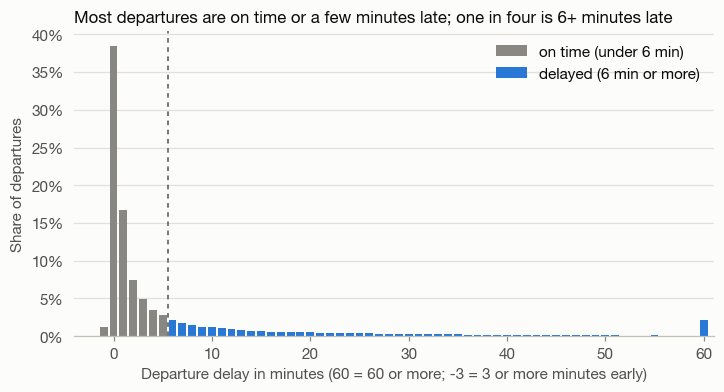

In [3]:
d = con.sql("SELECT LEAST(GREATEST(dep_delay, -3), 60) AS delay, COUNT(*) AS n FROM dev GROUP BY 1 ORDER BY 1").df()
total = d["n"].sum()
fig, ax = plt.subplots(figsize=(7.5, 3.6))
late = d["delay"] >= config.DELAY_THRESHOLD_MIN
ax.bar(d.loc[~late, "delay"], 100 * d.loc[~late, "n"] / total, width=0.8, color=MUTED, label="on time (under 6 min)")
ax.bar(d.loc[late, "delay"], 100 * d.loc[late, "n"] / total, width=0.8, color=BLUE, label="delayed (6 min or more)")
ax.axvline(config.DELAY_THRESHOLD_MIN - 0.5, color=INK2, linewidth=1, linestyle=(0, (3, 3)))
ax.set_xlim(-4, 61); ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel("Departure delay in minutes (60 = 60 or more; -3 = 3 or more minutes early)"); ax.set_ylabel("Share of departures")
ax.set_title("Most departures are on time or a few minutes late; one in four is 6+ minutes late")
ax.legend(loc="upper right")
save(fig, "eda_delay_distribution")
q = con.sql("SELECT ROUND(100*AVG((dep_delay = 0)::INT),1) AS exactly_0, ROUND(100*AVG((dep_delay BETWEEN 1 AND 5)::INT),1) AS min_1_5, ROUND(100*AVG((dep_delay BETWEEN 6 AND 15)::INT),1) AS min_6_15, ROUND(100*AVG((dep_delay BETWEEN 16 AND 59)::INT),1) AS min_16_59, ROUND(100*AVG((dep_delay >= 60)::INT),1) AS min_60_plus, MEDIAN(dep_delay) AS median, ROUND(AVG(dep_delay),1) AS mean FROM dev").df()
print(q.to_string(index=False))

**What we see.** 38.5% of departures leave exactly on time, 35.4% are 1–5 minutes late, 12.0% are 6–15 minutes late, 10.7% are 16–59 minutes late and 2.1% are an hour or more late. The median delay is 1 minute, the mean 7.1 minutes.

**What it means.** The distribution is strongly skewed: a few very late trains pull the mean far above the median. A model that predicts minutes would mostly learn those rare cases. This supports the binary target (D2): 24.8% of the departures in this period are delayed.

## 2. Who is late? Service and line

saved reports/figures/eda_delay_by_service.png
      service      n  pct
     regional 120721  8.5
long_distance  71855 48.8
        night   5706 66.6


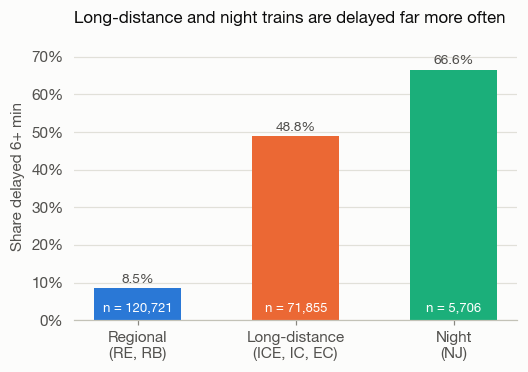

In [4]:
s = con.sql("SELECT service, COUNT(*) AS n, 100 * AVG(delayed) AS pct FROM dev GROUP BY 1 ORDER BY n DESC").df()
s = s[s["service"].isin(SERVICE_COLOR)]
fig, ax = plt.subplots(figsize=(5.2, 3.4))
bars = ax.bar([SERVICE_LABEL[x].replace(" (", "\n(") for x in s["service"]], s["pct"], width=0.55, color=[SERVICE_COLOR[x] for x in s["service"]])
label_bars(ax, bars, s["pct"])
for bar, n in zip(bars, s["n"]):
    ax.text(bar.get_x() + bar.get_width() / 2, 1.5, f"n = {n:,}", ha="center", va="bottom", color="#ffffff", fontsize=8.5)
ax.set_ylim(0, max(s["pct"]) * 1.15); ax.yaxis.set_major_formatter(PCT); ax.set_ylabel("Share delayed 6+ min")
ax.set_title("Long-distance and night trains are delayed far more often")
save(fig, "eda_delay_by_service")
print(s.round(1).to_string(index=False))

saved reports/figures/eda_delay_by_line.png


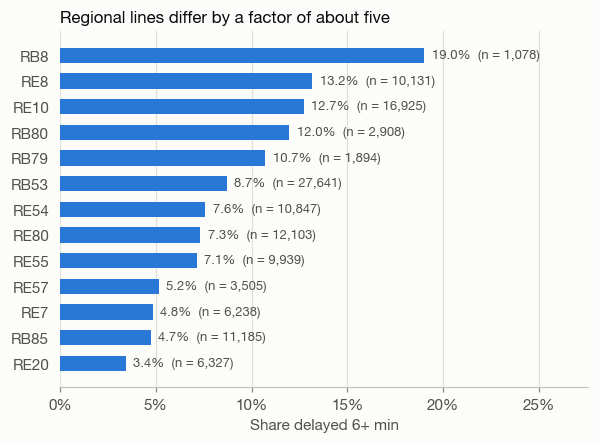

In [5]:
l = con.sql("SELECT line_id, COUNT(*) AS n, 100 * AVG(delayed) AS pct FROM dev WHERE service = 'regional' GROUP BY 1 ORDER BY pct").df()
fig, ax = plt.subplots(figsize=(6.2, 4.2))
bars = ax.barh(l["line_id"], l["pct"], height=0.6, color=BLUE)
for bar, v, n in zip(bars, l["pct"], l["n"]):
    ax.text(v + 0.4, bar.get_y() + bar.get_height() / 2, f"{v:.1f}%  (n = {n:,})", va="center", color=INK2, fontsize=8.5)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlim(0, l["pct"].max() * 1.45); ax.xaxis.set_major_formatter(PCT); ax.set_xlabel("Share delayed 6+ min")
ax.set_title("Regional lines differ by a factor of about five")
save(fig, "eda_delay_by_line")

**What we see.** Regional trains are delayed 8.5% of the time (n = 120,721), long-distance trains 48.8% (n = 71,855) and night trains 66.6% (n = 5,706). Among regional lines the rate runs from 3.4% (RE20) to 19.0% (RB8).

**What it means.** The overall rate of 24.8% is a mix of two very different groups. The service is the strongest single piece of timetable information, which is why the rule-based baseline B1 (service × hour) already reaches a ROC-AUC of 0.79. Results must be reported per service, not only overall: a model can look good overall by separating regional from long-distance trains and still be poor inside each group.

## 3. Trains that pass through and trains that start at Würzburg

saved reports/figures/eda_delay_through_vs_start.png
      service  is_through     n  pct
long_distance       False   205  8.3
long_distance        True 71650 49.0
     regional       False 92894  8.9
     regional        True 27827  7.4


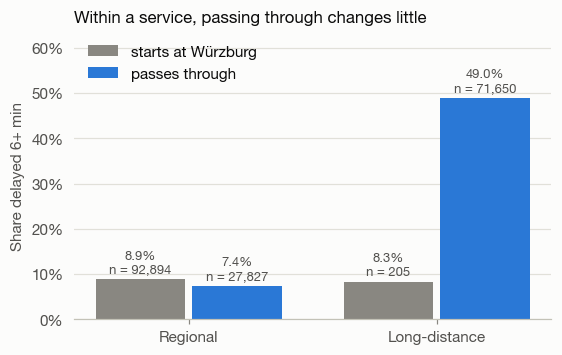

In [6]:
t = con.sql("SELECT service, is_through, COUNT(*) AS n, 100 * AVG(delayed) AS pct FROM dev WHERE service IN ('regional', 'long_distance') GROUP BY 1, 2 ORDER BY 1, 2").df()
fig, ax = plt.subplots(figsize=(5.6, 3.4))
groups = ["regional", "long_distance"]; width = 0.36
for k, (flag, label, color) in enumerate([(False, "starts at Würzburg", MUTED), (True, "passes through", BLUE)]):
    part = t[t["is_through"] == flag].set_index("service").reindex(groups)
    xs = [i + (k - 0.5) * (width + 0.03) for i in range(len(groups))]
    bars = ax.bar(xs, part["pct"], width=width, color=color, label=label)
    for bar, v, n in zip(bars, part["pct"], part["n"]):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.8, f"{v:.1f}%\nn = {n:,}", ha="center", va="bottom", color=INK2, fontsize=8.5)
ax.set_xticks(range(len(groups))); ax.set_xticklabels(["Regional", "Long-distance"])
ax.set_ylim(0, t["pct"].max() * 1.3); ax.yaxis.set_major_formatter(PCT); ax.set_ylabel("Share delayed 6+ min")
ax.set_title("Within a service, passing through changes little")
ax.legend(loc="upper left")
save(fig, "eda_delay_through_vs_start")
print(t.round(1).to_string(index=False))

**What we see.** Inside a service, passing through makes little difference: regional trains that pass through are delayed 7.4% of the time, regional trains that start at Würzburg 8.9%. Almost all long-distance trains pass through (71,650 of 71,855); the 205 that start here are too few to compare.

**What it means.** Taken over all trains, through trains are delayed about four times as often as trains that start at Würzburg (about 36% against 9%). This figure shows that the gap comes from the service mix, not from passing through: through trains are mostly long-distance trains. Regional through trains wait about 10 minutes at Würzburg (median planned stop), which can absorb a late arrival. Consequences: `is_through` adds little once the service is known, and the scenario B rows are dominated by long-distance trains, so scenario B results are reported by service.

## 4. When? Hour, weekday, month

saved reports/figures/eda_delay_by_hour.png
service       long_distance  regional
planned_hour                         
0                       NaN      14.4
1                      63.7       NaN
3                      38.5       NaN
4                      39.5       7.8
5                      12.2       6.7
6                      27.0       6.2
7                      27.3       7.9
8                      28.9       6.2
9                      36.5       6.9
10                     44.8       6.3
11                     47.6       6.6
12                     52.2       6.5
13                     49.2       8.0
14                     52.3       8.6
15                     42.5      10.0
16                     53.4       8.8
17                     52.5       9.5
18                     59.2      10.3
19                     58.1      10.4
20                     61.3       8.4
21                     54.5      10.5
22                     65.9      16.5
23                     77.4      11.6


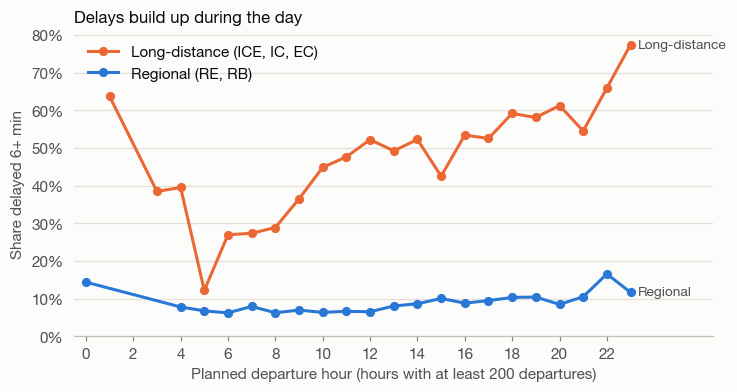

In [7]:
h = con.sql("SELECT service, planned_hour, COUNT(*) AS n, 100 * AVG(delayed) AS pct FROM dev WHERE service IN ('regional', 'long_distance') GROUP BY 1, 2 HAVING COUNT(*) >= 200 ORDER BY 1, 2").df()
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for service in ["long_distance", "regional"]:
    part = h[h["service"] == service]
    ax.plot(part["planned_hour"], part["pct"], marker="o", color=SERVICE_COLOR[service], label=SERVICE_LABEL[service])
    last = part.iloc[-1]
    ax.text(last["planned_hour"] + 0.3, last["pct"], SERVICE_LABEL[service].split(" (")[0], color=INK2, va="center", fontsize=9)
ax.set_xticks(range(0, 24, 2)); ax.set_xlim(-0.5, 26.5); ax.set_ylim(0, None); ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel("Planned departure hour (hours with at least 200 departures)"); ax.set_ylabel("Share delayed 6+ min")
ax.set_title("Delays build up during the day")
ax.legend(loc="upper left")
save(fig, "eda_delay_by_hour")
print(h.pivot(index="planned_hour", columns="service", values="pct").round(1).to_string())

saved reports/figures/eda_delay_by_weekday.png
             n   pct
weekday             
Mon      29428  22.8
Tue      29696  26.1
Wed      29209  26.4
Thu      29119  27.7
Fri      29448  26.0
Sat      26108  22.4
Sun      25369  21.5


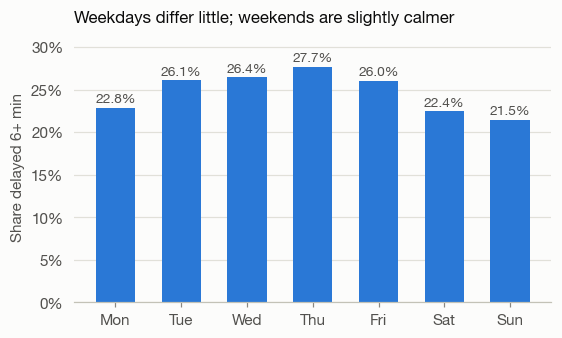

In [8]:
w = con.sql("SELECT weekday, COUNT(*) AS n, 100 * AVG(delayed) AS pct FROM dev GROUP BY 1").df()
names = {1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat", 0: "Sun"}
w = w.set_index("weekday").loc[[1, 2, 3, 4, 5, 6, 0]]
fig, ax = plt.subplots(figsize=(5.6, 3.2))
bars = ax.bar([names[i] for i in w.index], w["pct"], width=0.6, color=BLUE)
label_bars(ax, bars, w["pct"], dy=0.3)
ax.set_ylim(0, w["pct"].max() * 1.15); ax.yaxis.set_major_formatter(PCT); ax.set_ylabel("Share delayed 6+ min")
ax.set_title("Weekdays differ little; weekends are slightly calmer")
save(fig, "eda_delay_by_weekday")
print(w.round(1).rename(index=names).to_string())

saved reports/figures/eda_delay_by_month.png
service     long_distance  regional
month                              
2024-07-01           56.3      10.1
2024-08-01           51.9       6.8
2024-09-01           47.9       7.9
2024-10-01           48.2       9.2
2024-11-01           49.2       9.4
2024-12-01           44.1       7.5
2025-01-01           51.4       8.0
2025-02-01           44.9       7.2
2025-03-01           40.6       5.5
2025-04-01           53.6       9.5
2025-05-01           48.1       7.9
2025-06-01           52.4       7.7
2025-07-01           53.2      10.9
2025-08-01           48.9       8.8
2025-09-01           52.4      11.7
2025-10-01           61.8       8.6
2025-11-01           58.5       7.4
2025-12-01           41.1       9.0
2026-01-01           54.7      10.3
2026-02-01           43.3       7.5
2026-03-01           39.0       9.7
2026-04-01           37.0       8.2
2026-05-01           36.7       7.4
2026-06-01           50.6       8.5


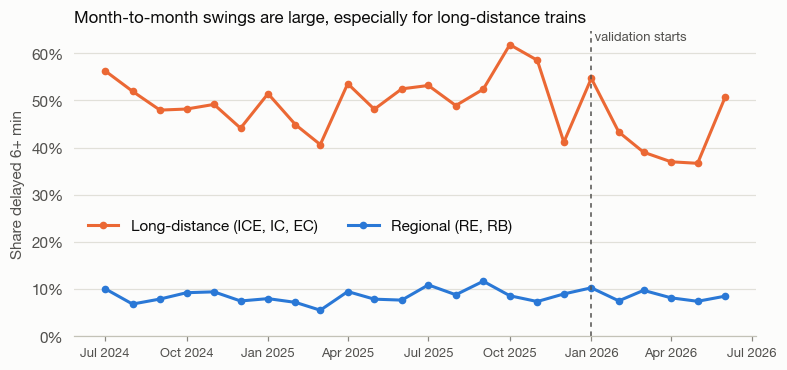

In [9]:
m = con.sql("SELECT month, service, COUNT(*) AS n, 100 * AVG(delayed) AS pct FROM dev WHERE service IN ('regional', 'long_distance') GROUP BY 1, 2 ORDER BY 1, 2").df()
fig, ax = plt.subplots(figsize=(8, 3.6))
for service in ["long_distance", "regional"]:
    part = m[m["service"] == service]
    ax.plot(part["month"], part["pct"], marker="o", markersize=4, color=SERVICE_COLOR[service], label=SERVICE_LABEL[service])
ax.axvline(pd.Timestamp(config.SPLITS["A"]["val"][0]), color=INK2, linewidth=1, linestyle=(0, (3, 3)))
ax.text(pd.Timestamp(config.SPLITS["A"]["val"][0]), ax.get_ylim()[1], " validation starts", color=INK2, fontsize=8.5, va="top")
ax.set_ylim(0, None); ax.yaxis.set_major_formatter(PCT); ax.set_ylabel("Share delayed 6+ min")
ax.set_title("Month-to-month swings are large, especially for long-distance trains")
month_axis(ax, every=3); ax.tick_params(axis="x", labelsize=8.5)
ax.legend(loc="center left", bbox_to_anchor=(0, 0.36), ncols=2)
save(fig, "eda_delay_by_month")
print(m.pivot(index="month", columns="service", values="pct").round(1).to_string())

**What we see.** Long-distance trains: the delay rate rises from about 27% at 6–8 h to 55–65% in the evening and 77% at 23 h. Regional trains stay between 6% and 10% for most of the day and reach 16.5% at 22 h. By weekday the rate lies between 21.5% (Sunday) and 27.7% (Thursday). By month, long-distance trains swing between 37% and 62%, regional trains between 5.5% and 11.7%, without a simple seasonal pattern (the highest values are October–November 2025, the lowest March–May 2026).

**What it means.** Hour matters, and it matters differently per service (an interaction that the logistic regression only sees if it is built by hand). The month-to-month swings are larger than the weekday effect: recent history (delay rate of the last weeks) is a plausible feature, and the validation period (22.0% delayed) is calmer than the training period (25.7%). A model tuned on validation meets a different base rate in other periods, which is one reason for reporting calibration.

## 5. What the cleaning step sets aside

saved reports/figures/eda_excluded_rows_by_month.png
  month  canceled  no_plan_record   bus
2024-07      2.89            1.20 10.24
2024-08      2.71            0.97  6.94
2024-09      3.55            0.88  4.43
2024-10      4.00            1.32  1.17
2024-11      2.76            1.18  0.41
2024-12      3.29            1.02  0.75
2025-01      3.25            1.03  0.32
2025-02      2.64            0.86  0.16
2025-03      2.97            1.55  0.68
2025-04      3.08            1.39  0.14
2025-05      2.03            0.83  0.15
2025-06      3.57            1.40  0.31
2025-07      4.03            5.03  0.60
2025-08      2.86            1.32  0.17
2025-09      2.83            1.37  0.10
2025-10      3.07            1.45  1.92
2025-11      2.19            2.10  1.89
2025-12      1.69            2.85  2.00
2026-01      2.55            5.68  5.20
2026-02      1.80            5.62  1.20
2026-03      2.60            5.36  0.53
2026-04      1.34            4.84  0.29
2026-05      1.22          

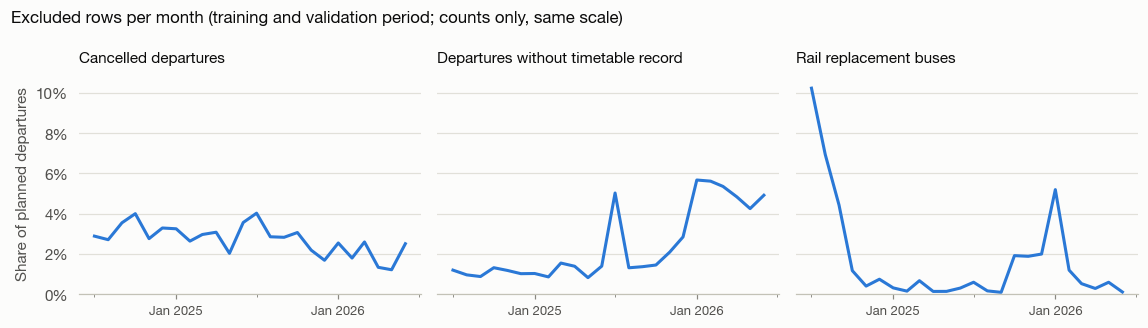

In [10]:
e = con.sql("""
    SELECT month,
           100 * AVG((exclude_reason = 'canceled')::INT)        AS canceled,
           100 * AVG((exclude_reason = 'no_plan_record')::INT)  AS no_plan_record,
           100 * AVG((exclude_reason = 'bus')::INT)             AS bus
    FROM (SELECT month, COALESCE(exclude_reason, '') AS exclude_reason FROM dev_all) GROUP BY 1 ORDER BY 1
""").df()
panels = [("canceled", "Cancelled departures"), ("no_plan_record", "Departures without timetable record"), ("bus", "Rail replacement buses")]
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3), sharey=True)
top = e[[c for c, _ in panels]].max().max() * 1.08
for ax, (col, title) in zip(axes, panels):
    ax.plot(e["month"], e[col], color=BLUE)
    ax.set_title(title, fontsize=10); ax.set_ylim(0, top); ax.yaxis.set_major_formatter(PCT)
    month_axis(ax, every=12); ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[7])); ax.tick_params(axis="x", labelsize=8.5)
axes[0].set_ylabel("Share of planned departures")
fig.suptitle("Excluded rows per month (training and validation period; counts only, same scale)", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
save(fig, "eda_excluded_rows_by_month")
print(e.assign(month=e["month"].dt.strftime("%Y-%m")).round(2).to_string(index=False))

**What we see.** Cancelled departures fall from about 3–4% of planned departures per month to 1–2.5% in 2026. Departures without a timetable record are about 1% until mid-2025 (with one spike of 5.0% in July 2025) and 4–6% from January 2026. Replacement buses are 10% of planned departures in July 2024 and 5% in January 2026 (construction periods), otherwise below 2%.

**What it means.** The exclusion rules do not remove a constant share of the data. The growing share of rows without a timetable record is the reason for the second sensitivity check (D18). This figure shows counts only; no delay information of excluded rows is used for modelling.

## 6. A change in how punctual departures are recorded

saved reports/figures/eda_exact_and_early_by_month.png
  month  exactly_on_time  early
2024-07            33.62   2.40
2024-08            34.55   2.46
2024-09            35.19   2.31
2024-10            33.22   1.97
2024-11            32.89   1.68
2024-12            37.55   1.62
2025-01            34.87   1.72
2025-02            36.10   1.88
2025-03            40.75   1.67
2025-04            34.48   1.15
2025-05            35.91   1.39
2025-06            36.59   1.77
2025-07            37.69   1.92
2025-08            41.68   1.98
2025-09            36.68   1.48
2025-10            39.86   1.80
2025-11            41.18   1.23
2025-12            46.26   0.15
2026-01            41.73   0.07
2026-02            43.70   0.11
2026-03            42.31   0.09
2026-04            42.92   0.05
2026-05            44.98   0.07
2026-06            42.20   0.06


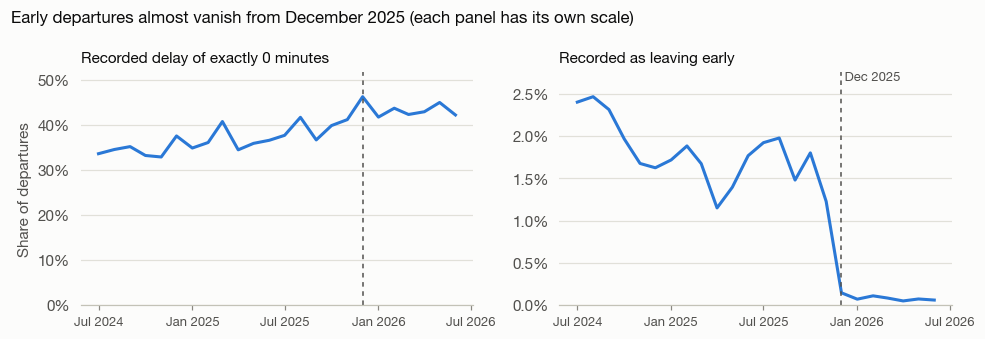

In [11]:
z = con.sql("SELECT month, 100 * AVG((dep_delay = 0)::INT) AS exactly_on_time, 100 * AVG((dep_delay < 0)::INT) AS early FROM dev GROUP BY 1 ORDER BY 1").df()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.1))
for ax, col, title in [(axes[0], "exactly_on_time", "Recorded delay of exactly 0 minutes"), (axes[1], "early", "Recorded as leaving early")]:
    ax.plot(z["month"], z[col], color=BLUE)
    ax.axvline(pd.Timestamp("2025-12-01"), color=INK2, linewidth=1, linestyle=(0, (3, 3)))
    ax.set_title(title, fontsize=10); ax.set_ylim(0, z[col].max() * 1.12)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=100, decimals=0 if col == "exactly_on_time" else 1))
    month_axis(ax); ax.tick_params(axis="x", labelsize=8.5)
axes[1].text(pd.Timestamp("2025-12-01"), axes[1].get_ylim()[1], " Dec 2025", color=INK2, fontsize=8.5, va="top")
axes[0].set_ylabel("Share of departures")
fig.suptitle("Early departures almost vanish from December 2025 (each panel has its own scale)", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
save(fig, "eda_exact_and_early_by_month")
print(z.assign(month=z["month"].dt.strftime("%Y-%m")).round(2).to_string(index=False))

**What we see.** The share of departures recorded with exactly 0 minutes of delay rises from about 34% (2024) to 42–46% (from December 2025). Departures recorded as early are 1.2–2.5% per month until November 2025 and at most 0.15% afterwards.

**What it means.** From December 2025 the source almost never reports an early departure; these now appear as 0 minutes. Part of the rise in "exactly on time" is therefore a change in recording, not in punctuality. The binary target is not affected (early and on-time departures are both "not delayed"), but a regression on minutes would be: delays would have to be clipped at 0 (D11).

## 7. Scenario B: do we know the previous stop? (coverage only, no delays; whole data period)

saved reports/figures/eda_previous_stop_coverage.png
service  long_distance  regional
month                           
2024-07           97.6       0.0
2025-09           96.3       0.0
2025-10           99.1       0.0
2025-11           99.6      93.2
2025-12           99.9      99.8
2026-06           98.9      99.5
2026-10           99.9      99.9


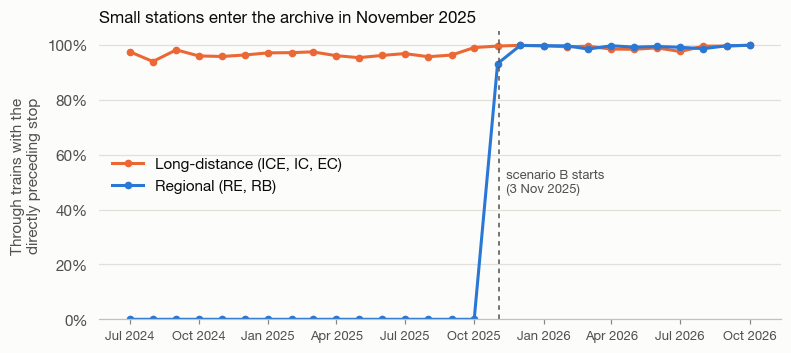

In [12]:
c = con.sql(f"""
    WITH last_prev AS (SELECT wuerzburg_id, MAX(train_line_station_num) AS num FROM read_parquet('{PREV}') WHERE NOT stop_canceled GROUP BY 1)
    SELECT date_trunc('month', w.departure_planned_time) AS month, w.service,
           100 * AVG(CASE WHEN p.num = w.train_line_station_num - 1 THEN 1.0 ELSE 0 END) AS direct_prev
    FROM read_parquet('{CLEAN}') w LEFT JOIN last_prev p ON p.wuerzburg_id = w.id
    WHERE w.exclude_reason IS NULL AND w.is_through AND w.service IN ('regional', 'long_distance') AND w.split_a IS NOT NULL
    GROUP BY 1, 2 ORDER BY 1, 2
""").df()
fig, ax = plt.subplots(figsize=(8, 3.4))
for service in ["long_distance", "regional"]:
    part = c[c["service"] == service]
    ax.plot(part["month"], part["direct_prev"], marker="o", markersize=4, color=SERVICE_COLOR[service], label=SERVICE_LABEL[service])
start = pd.Timestamp(config.FULL_COVERAGE_START)
ax.axvline(start, color=INK2, linewidth=1, linestyle=(0, (3, 3)))
ax.text(start, 50, "  scenario B starts\n  (3 Nov 2025)", color=INK2, fontsize=8.5, va="center")
ax.set_ylim(0, 105); ax.yaxis.set_major_formatter(PCT); ax.set_ylabel("Through trains with the\ndirectly preceding stop")
ax.set_title("Small stations enter the archive in November 2025")
month_axis(ax, every=3); ax.tick_params(axis="x", labelsize=8.5)
ax.legend(loc="center left")
save(fig, "eda_previous_stop_coverage")
print(c.assign(month=c["month"].dt.strftime("%Y-%m")).pivot(index="month", columns="service", values="direct_prev").round(1).iloc[[0, 14, 15, 16, 17, 23, -1]].to_string())

**What we see.** For long-distance through trains the directly preceding stop is in the data in 94–98% of cases before November 2025 and in about 99–100% afterwards. For regional through trains it is 0% until October 2025, 93% in November 2025 and practically 100% from December 2025.

**What it means.** Before November 2025 the archive holds only about 100 large stations, so the small stops before Würzburg are missing for regional trains. Scenario B is therefore trained only from 3 November 2025 (D6).

## 8. Scenario B: how much does the previous stop tell us?

saved reports/figures/eda_propagation_previous_stop.png
       bin    lo    n  pct
0 or early -13.0 8135  6.7
       1-2   1.0 6916  8.8
       3-5   3.0 4343 14.9
       6-9   6.0 3028 37.8
     10-19  10.0 4000 80.1
       20+  20.0 5524 96.9
    n  pct_delayed  corr
31946         36.0 0.915


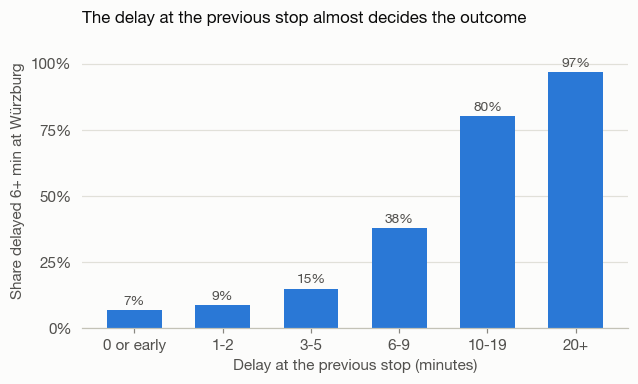

In [13]:
con.execute(f"""
    CREATE OR REPLACE VIEW prop AS
    WITH last_stop AS (
        SELECT wuerzburg_id,
               arg_max(stop_delay, COALESCE(departure_planned_time, arrival_planned_time)) AS prev_delay,
               MAX(COALESCE(departure_planned_time, arrival_planned_time))               AS prev_planned
        FROM read_parquet('{PREV}') WHERE NOT stop_canceled AND stop_delay IS NOT NULL GROUP BY 1)
    SELECT w.service, w.delayed, w.dep_delay, s.prev_delay,
           (epoch(w.departure_planned_time) - epoch(s.prev_planned)) / 60 AS minutes_from_prev
    FROM read_parquet('{CLEAN}') w JOIN last_stop s ON s.wuerzburg_id = w.id
    WHERE w.exclude_reason IS NULL AND w.is_through AND w.has_prev_stop AND w.split_b IN ('train', 'val')
""")
b = con.sql("""
    SELECT CASE WHEN prev_delay <= 0 THEN '0 or early' WHEN prev_delay <= 2 THEN '1-2' WHEN prev_delay <= 5 THEN '3-5'
                WHEN prev_delay <= 9 THEN '6-9' WHEN prev_delay <= 19 THEN '10-19' ELSE '20+' END AS bin,
           MIN(prev_delay) AS lo, COUNT(*) AS n, 100 * AVG(delayed) AS pct
    FROM prop GROUP BY 1 ORDER BY lo
""").df()
fig, ax = plt.subplots(figsize=(6.4, 3.5))
bars = ax.bar(b["bin"], b["pct"], width=0.62, color=BLUE)
label_bars(ax, bars, b["pct"], fmt="{:.0f}%", dy=1)
ax.set_ylim(0, 112); ax.yaxis.set_major_formatter(PCT); ax.set_yticks([0, 25, 50, 75, 100])
ax.set_xlabel("Delay at the previous stop (minutes)"); ax.set_ylabel("Share delayed 6+ min at Würzburg")
ax.set_title("The delay at the previous stop almost decides the outcome")
save(fig, "eda_propagation_previous_stop")
print(b.round(1).to_string(index=False))
print(con.sql("SELECT COUNT(*) AS n, ROUND(100 * AVG(delayed), 1) AS pct_delayed, ROUND(corr(prev_delay, dep_delay), 3) AS corr FROM prop").df().to_string(index=False))

saved reports/figures/eda_scenario_b_horizon.png
                   n   p10  median    p90
service                                  
night           1813  53.0    78.0  171.0
long_distance  21034  33.0    54.0   62.0
regional        9081  14.0    16.0   41.0


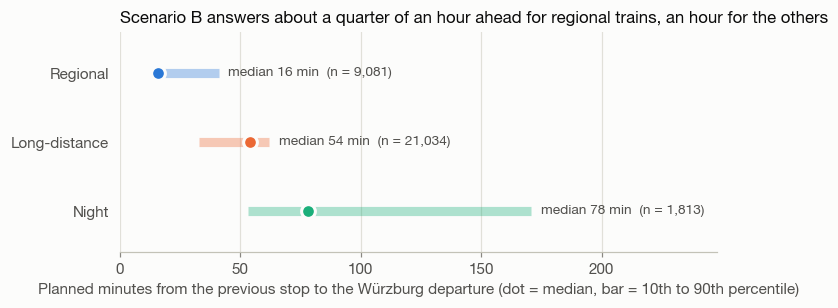

In [14]:
hz = con.sql("""
    SELECT service, COUNT(*) AS n, QUANTILE_CONT(minutes_from_prev, 0.1) AS p10, MEDIAN(minutes_from_prev) AS median,
           QUANTILE_CONT(minutes_from_prev, 0.9) AS p90
    FROM prop WHERE service IN ('regional', 'long_distance', 'night') GROUP BY 1
""").df().set_index("service").loc[["night", "long_distance", "regional"]]
fig, ax = plt.subplots(figsize=(7, 2.6))
for i, (service, row) in enumerate(hz.iterrows()):
    ax.hlines(i, row["p10"], row["p90"], color=SERVICE_COLOR[service], linewidth=6, alpha=0.35)
    ax.plot(row["median"], i, "o", color=SERVICE_COLOR[service], markersize=9, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.text(row["p90"] + 4, i, f"median {row['median']:.0f} min  (n = {int(row['n']):,})", va="center", color=INK2, fontsize=9)
ax.set_yticks(range(len(hz))); ax.set_yticklabels([SERVICE_LABEL[s].split(" (")[0] for s in hz.index])
ax.set_ylim(-0.6, len(hz) - 0.4); ax.set_xlim(0, hz["p90"].max() * 1.45)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("Planned minutes from the previous stop to the Würzburg departure (dot = median, bar = 10th to 90th percentile)")
ax.set_title("Scenario B answers about a quarter of an hour ahead for regional trains, an hour for the others")
save(fig, "eda_scenario_b_horizon")
print(hz.round(0).to_string())

**What we see** (scenario B training and validation rows, 31,946 through trains with an earlier stop, 36.0% delayed). The delay at the previous stop and the departure delay at Würzburg correlate with 0.915. If the train was on time or early at the previous stop, 6.7% leave Würzburg late; with 3–5 minutes it is 14.9%; with 6–9 minutes only 37.8%; with 10–19 minutes 80.1%; with 20 minutes or more 96.9%. The previous stop is 16 planned minutes before the Würzburg departure for regional trains (median), 54 minutes for long-distance trains and 78 minutes for night trains.

**What it means.** The previous-stop delay carries most of the information, which is why scenario B needs its own baseline B3 (D17). The interesting range is 3–9 minutes: most trains that are 6–9 minutes late at the previous stop still leave Würzburg less than 6 minutes late (they catch up on the way or during the stop), so the simple rule is wrong there most often. That is where a model can add something, for example by using the planned stop time at Würzburg and the time left to catch up. The horizon bins planned in D13 (under 10, 10–30, over 30 minutes) do not fit the data: no scenario B row is under 10 minutes and every long-distance train is over 30. Bins by service, or 10–20, 20–45 and over 45 minutes, would be more useful (to decide with the results table).

## 9. Summary for the report

1. **Target.** 24.8% of departures in the training and validation period are delayed; the delay distribution is strongly skewed (median 1 min, mean 7.1 min).
2. **Service dominates.** Regional 8.5%, long-distance 48.8%, night 66.6%; regional lines from 3.4% to 19.0%. All results should be shown per service.
3. **Time.** Long-distance delays build up during the day (27% in the morning, over 60% late in the evening); weekday effects are small; months swing strongly without a clear season.
4. **Through trains.** The large gap between through trains and trains starting at Würzburg is a service effect; inside regional trains it disappears (7.4% against 8.9%).
5. **Propagation.** The previous-stop delay almost decides the outcome (correlation 0.915), except in the range of 3–9 minutes, where trains often recover. Scenario B answers 16 minutes ahead for regional and about an hour ahead for long-distance trains.
6. **Data caveats for the report.** Rows without timetable record grow from 1% to 5% of planned departures; early departures are no longer recorded from December 2025; small stations exist only from November 2025.

Open point from this notebook: the horizon bins of D13 should be redefined (see section 8).